# Task 2 — Multimodal ICD coding of hospital admissions: results overview

This notebook goes through the **main results** of the project. It reads only the small result
files shipped in `results/` (metrics, training history, retrieval scores). It needs **no MIMIC data
and no GPU** and runs in a few seconds.

To retrain the models and regenerate these files, see the commands in `README.md`. A rerun writes
the same files to `outputs/<run>/`. Set `RESULTS_DIR = ROOT / "outputs"` below to view your own runs.

**Task.** For each hospital admission (`hadm_id`) in MIMIC-IV, predict its set of ICD codes
(multi-label, 6,085 diagnosis + procedure codes) from the admission's **chest X-rays** (MIMIC-CXR
JPGs) and their **radiology reports**.

**Model** (all experiments):
1. Frozen encoders: **DINOv3 ViT-S/16** per image (CLS token, 384-d) and **MedCLIP** text encoder per report (512-d).
   One vector per study (an admission has 1 to many studies).
2. Trainable heads: per-modality projection to 512-d, mean over studies, then **fusion** of the image and text
   admission vectors, plus a **shared linear classifier** over 6,085 codes.
3. Loss: `0.25·BCE(image) + 0.25·BCE(text) + 0.5·BCE(fused)` plus, in some arms, `λ·SupCon`.
   SupCon is a supervised contrastive term that pulls together admissions with overlapping codes.

**Metrics.** Main metric: **micro-averaged average precision (AP)** of the fused scores over all
(admission, code) pairs. Also: precision@5, AP at each ICD hierarchy level (L1 = chapter … L5), and
retrieval (mean Jaccard overlap between a test admission's codes and those of its 10 nearest training admissions).
Test set: 2,015 admissions. Baseline: predict each code with its training frequency.

In [1]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":          # works from the repo root or from notebooks/
    ROOT = ROOT.parent
RESULTS_DIR = ROOT / "results"        # or ROOT / "outputs" for your own reruns
assert RESULTS_DIR.is_dir(), f"results folder not found under {ROOT}"
pd.set_option("display.precision", 4)


def load_run(name):
    # results.json (+ retrieval.json) of one run, or None if the run is missing.
    folder = RESULTS_DIR / name
    if not (folder / "results.json").exists():
        return None
    run = json.loads((folder / "results.json").read_text())
    retrieval = folder / "retrieval.json"
    run["retrieval"] = json.loads(retrieval.read_text()) if retrieval.exists() else None
    return run


def summary(run, modality="fused"):
    # Headline test metrics of one run.
    test = run["test"]["modalities"][modality]
    row = {"micro AP": test["micro_ap"], "P@5": test["precision_at_5"], "R@5": test["recall_at_5"],
           "macro AP": test["macro_ap_valid"], "best epoch": run["best_epoch"]}
    for level in (1, 3, 5):
        row[f"L{level} AP"] = run["test"]["cm_hierarchy"][f"level_{level}"][modality]["micro_ap"]
    if run.get("retrieval"):
        row["retrieval Jaccard@10"] = run["retrieval"][modality]["mean_jaccard"]
    return row


SEEDS = (42, 43, 44)
BCE = {s: load_run(f"experiment01_admission_unweighted_textfix_e120_cos_s{s}") for s in SEEDS}
SUPCON = {s: load_run(f"experiment03_supcon_w0.001_e120_cos_s{s}") for s in SEEDS}
FINETUNE = {arm: load_run(f"experiment05_ft_supcon_w0.001_{arm}_s42") for arm in ("frozen", "img", "txt", "both")}
HSUPCON = load_run("experiment04_hsupcon_w0.001_e120_cos_s42")
print("runs found:", sum(r is not None for r in [*BCE.values(), *SUPCON.values(), *FINETUNE.values(), HSUPCON]), "of 11")

runs found: 11 of 11


## 1. Progression of the experiments

Each step changed one thing. The table uses `results/all_results_comparison.csv`, the log of every
evaluated run (fused scores on the test set, exact codes). Seeded rounds show the mean over seeds.

| step | change |
|---|---|
| frequency baseline | constant scores = training prevalence of each code |
| Exp1 weighted BCE | positive-class weights (capped at 50) — **worse** than the baseline |
| Exp1 unweighted BCE | plain BCE, 20 epochs |
| + text fix | MedCLIP pooling ignores padding tokens; before, a report's embedding depended on its batch |
| + 60 epochs | training was far from converged (best epoch was always the last) |
| + 120 epochs, cosine LR | converged (validation flat for the last ~20 epochs) |
| + Jaccard SupCon λ=0.001 | contrastive term weighted by code overlap |
| hierarchy SupCon instead | Round 4 SupCon arm with hierarchy-aware pair weights instead of Jaccard, seed 42 — no gain, so Jaccard SupCon stays the final loss |
| + fine-tune encoders | final Jaccard SupCon model with the last 2 blocks of DINOv3 and of BERT unfrozen, seed 42 |

In [2]:
table = pd.read_csv(RESULTS_DIR / "all_results_comparison.csv")
test = table[(table.cohort == "test") & (table.evaluation == "exact_all_targets")]


def rows(pattern):
    sel = test[test.method.str.fullmatch(pattern)]
    return sel[["micro_ap", "precision_at_5", "macro_ap_valid"]].agg(["mean", "std", "count"])


steps = [
    ("frequency baseline", "frequency_baseline"),
    ("Exp1 weighted BCE, 20 ep", r"weighted_bce/fused"),
    ("Exp1 unweighted BCE, 20 ep", r"unweighted_bce/fused"),
    ("+ text fix, 20 ep", r"textfix_bce/fused"),
    ("+ 60 epochs (3 seeds)", r"textfix_bce_e60_s\d+/fused"),
    ("+ 120 ep cosine LR (3 seeds)", r"textfix_bce_e120cos_s\d+/fused"),
    ("+ Jaccard SupCon (3 seeds)", r"supcon_w0\.001_e120cos_s\d+/fused"),
    ("hierarchy SupCon instead (s42)", r"hsupcon_w0\.001_e120cos_s42/fused"),
    ("+ fine-tune both encoders (s42)", r"ft_supcon_w0\.001_both_s42/fused"),
]
progress = pd.DataFrame(
    {name: {"test micro AP": r.loc["mean", "micro_ap"], "± std": r.loc["std", "micro_ap"],
            "P@5": r.loc["mean", "precision_at_5"], "macro AP": r.loc["mean", "macro_ap_valid"],
            "runs": int(r.loc["count", "micro_ap"])}
     for name, pattern in steps for r in [rows(pattern)]}).T
progress

,test micro AP,± std,P@5,macro AP,runs
frequency baseline,0.1408,NaN,0.3606,0.0064,1.0
"Exp1 weighted BCE, 20 ep",0.0854,NaN,0.1531,0.0220,1.0
"Exp1 unweighted BCE, 20 ep",0.1771,NaN,0.3949,0.0185,1.0
"+ text fix, 20 ep",0.1782,NaN,0.3955,0.0184,1.0
+ 60 epochs (3 seeds),0.2100,0.0012,0.4246,0.0352,3.0
+ 120 ep cosine LR (3 seeds),0.2180,0.0003,0.4304,0.0400,3.0
+ Jaccard SupCon (3 seeds),0.2205,0.0004,0.4366,0.0410,3.0
hierarchy SupCon instead (s42),0.2200,NaN,0.4354,0.0408,1.0
+ fine-tune both encoders (s42),0.2227,NaN,0.4411,0.0434,1.0


The same progression as a chart. Grey bars are the two reference rows (frequency baseline and weighted BCE), blue bars are the steps of the model; error bars show the standard deviation over seeds where a step was run with 3 seeds.

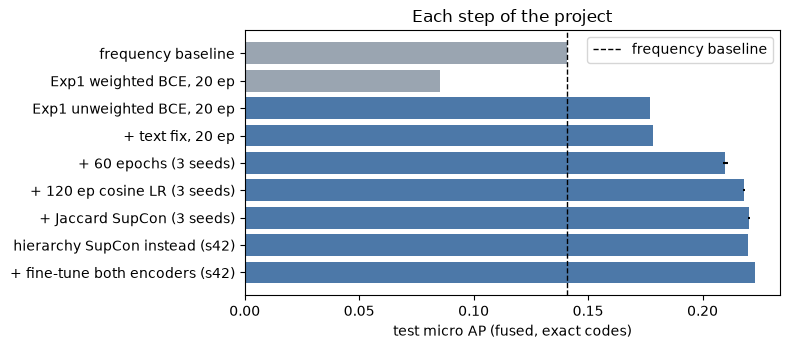

In [3]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(progress.index[::-1], progress["test micro AP"][::-1], xerr=progress["± std"][::-1].fillna(0),
        color=(["#9aa5b1"] * 2 + ["#4c78a8"] * (len(progress) - 2))[::-1])  # grey = the two reference rows
ax.axvline(progress.loc["frequency baseline", "test micro AP"], color="k", ls="--", lw=1, label="frequency baseline")
ax.set_xlabel("test micro AP (fused, exact codes)")
ax.legend(loc="upper right"); ax.set_title("Each step of the project")
plt.tight_layout(); plt.show()

## 2. Main experiment (Round 4): BCE vs Jaccard-weighted SupCon, 3 seeds

Frozen features, 120 epochs, cosine LR 1e-3 → 1e-5, early-stop patience 20, model selected on
validation fused micro AP. SupCon weights each pair of admissions by the **Jaccard overlap of their
code sets**. Plain "share at least one code" positives would be useless here, because 70 % of random
admission pairs share a code. λ = 0.001 because the SupCon gradient is about 500× larger than the BCE gradient.

Both arms use the same seed, so we report **paired** per-seed differences.

In [4]:
per_seed = pd.concat({
    "BCE": pd.DataFrame({s: summary(r) for s, r in BCE.items() if r}).T,
    "BCE + SupCon": pd.DataFrame({s: summary(r) for s, r in SUPCON.items() if r}).T,
}, names=["arm", "seed"])
display(per_seed)
display(per_seed.groupby(level="arm").agg(["mean", "std"]).T.unstack(level=-1).round(4))

paired = (per_seed.loc["BCE + SupCon"] - per_seed.loc["BCE"]).drop(columns="best epoch")
print("Paired difference SupCon − BCE per seed:")
display(paired)
print("SupCon better on", int((paired["micro AP"] > 0).sum()), "of", len(paired), "seeds; mean Δ micro AP =",
      round(paired["micro AP"].mean(), 4))

micro AP     P@5     R@5  macro AP  best epoch   L1 AP  \
arm          seed                                                           
BCE          42      0.2177  0.4315  0.1266    0.0400       112.0  0.6658   
             43      0.2179  0.4292  0.1254    0.0392       117.0  0.6662   
             44      0.2184  0.4305  0.1265    0.0408       119.0  0.6679   
BCE + SupCon 42      0.2203  0.4372  0.1286    0.0413       112.0  0.6699   
             43      0.2209  0.4374  0.1287    0.0412       112.0  0.6712   
             44      0.2202  0.4352  0.1280    0.0406       109.0  0.6685   

                    L3 AP   L5 AP  retrieval Jaccard@10  
arm          seed                                        
BCE          42    0.2984  0.2186                0.0692  
             43    0.2982  0.2186                0.0688  
             44    0.2991  0.2192                0.0694  
BCE + SupCon 42    0.3011  0.2212                0.0700  
             43    0.3019  0.2218                0.0701  
             44    0.3003  0.2211                0.0700

arm                        BCE         BCE + SupCon        
                          mean     std         mean     std
micro AP                0.2180  0.0003       0.2205  0.0004
P@5                     0.4304  0.0011       0.4366  0.0012
R@5                     0.1262  0.0007       0.1284  0.0004
macro AP                0.0400  0.0008       0.0410  0.0004
best epoch            116.0000  3.6056     111.0000  1.7321
L1 AP                   0.6666  0.0011       0.6699  0.0014
L3 AP                   0.2986  0.0005       0.3011  0.0008
L5 AP                   0.2188  0.0003       0.2213  0.0004
retrieval Jaccard@10    0.0691  0.0003       0.0701  0.0000

Paired difference SupCon − BCE per seed:


,micro AP,P@5,R@5,macro AP,L1 AP,L3 AP,L5 AP,retrieval Jaccard@10
seed,,,,,,,,
42,0.0025,0.0058,0.0020,0.0012,0.0041,0.0027,0.0025,0.0009
43,0.0030,0.0082,0.0033,0.0020,0.0051,0.0037,0.0032,0.0012
44,0.0018,0.0048,0.0015,-0.0002,0.0006,0.0012,0.0019,0.0006


SupCon better on 3 of 3 seeds; mean Δ micro AP = 0.0025


**Reading.** SupCon gives a small but **consistent** gain: about +0.0025 micro AP, positive on all 3
seeds and larger than the seed-to-seed spread (std ≈ 0.0004). It also improves P@5 and retrieval. The
fused model beats each single modality. Image and text alone reach similar AP.

In [5]:
modal = pd.DataFrame({
    (arm, m): {"micro AP": np.mean([runs[s]["test"]["modalities"][m]["micro_ap"] for s in SEEDS]),
               "P@5": np.mean([runs[s]["test"]["modalities"][m]["precision_at_5"] for s in SEEDS])}
    for arm, runs in (("BCE", BCE), ("BCE + SupCon", SUPCON)) for m in ("image", "text", "fused")}).T
modal

micro AP     P@5
BCE          image    0.1894  0.4122
             text     0.1835  0.4052
             fused    0.2180  0.4304
BCE + SupCon image    0.1906  0.4142
             text     0.1830  0.4066
             fused    0.2205  0.4366

### Learning curves

Validation fused micro AP per epoch, seed 42. The light validation epochs report micro metrics only.
Curves are flat over the last 20 epochs, so the frozen-feature model has **converged**. More epochs
will not help.

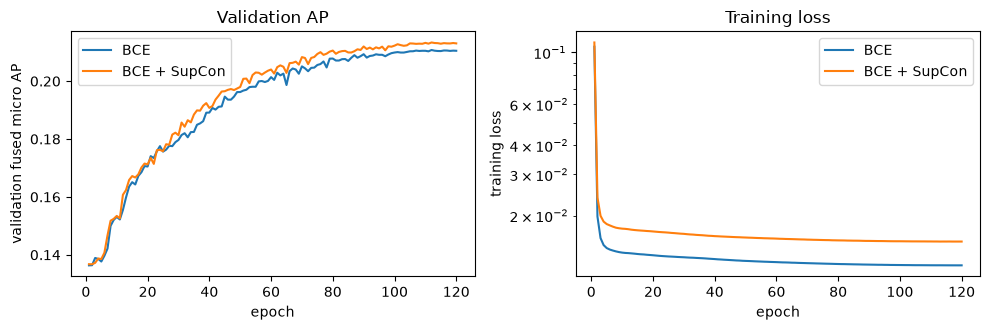

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
for name, run in (("BCE", BCE[42]), ("BCE + SupCon", SUPCON[42])):
    epochs = [h["epoch"] for h in run["history"]]
    axes[0].plot(epochs, [h["validation"]["modalities"]["fused"]["micro_ap"] for h in run["history"]], label=name)
    axes[1].plot(epochs, [h["train"]["loss"] for h in run["history"]], label=name)
axes[0].set(xlabel="epoch", ylabel="validation fused micro AP", title="Validation AP")
axes[1].set(xlabel="epoch", ylabel="training loss", title="Training loss", yscale="log")
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()

### Accuracy along the ICD hierarchy

Diagnosis codes are evaluated again after truncating them to their ancestors: L1 = chapter … L5 =
the most specific level. Coarse categories are much easier. Most of the low exact-code AP is
**subtype granularity** that an X-ray or report cannot reveal (e.g. 428.0 vs 428.23).
Note: L5 has 3,280 classes, the diagnosis codes only; "exact" also includes the 2,805 procedure codes.

In [7]:
levels = pd.DataFrame({
    arm: {f"L{l}": np.mean([runs[s]["test"]["cm_hierarchy"][f"level_{l}"]["fused"]["micro_ap"] for s in SEEDS])
          for l in range(1, 6)}
    for arm, runs in (("BCE", BCE), ("BCE + SupCon", SUPCON))})
levels.loc["exact"] = [per_seed.loc[a]["micro AP"].mean() for a in levels.columns]
levels["#classes"] = [BCE[42]["test"]["cm_hierarchy"][f"level_{l}"]["class_count"] for l in range(1, 6)] + [6085]
levels

,BCE,BCE + SupCon,#classes
L1,0.6666,0.6699,51
L2,0.4372,0.4408,279
L3,0.2986,0.3011,1088
L4,0.2302,0.2329,2710
L5,0.2188,0.2213,3280
exact,0.2180,0.2205,6085


## 3. Round 6: hierarchy-aware SupCon (seed 42)

Same as the Round 4 SupCon arm, but a pair's weight is the **depth-weighted mean of the Jaccard
overlaps at each hierarchy level** (L1…L5 + exact code, weights 1…6). A plain average was rejected:
98 % of random pairs share an L1 chapter, so it would make almost every pair positive.

In [8]:
if HSUPCON is None:
    print("Round 6 results not found in", RESULTS_DIR)
else:
    r6 = pd.DataFrame({"Jaccard SupCon (Round 4, s42)": summary(SUPCON[42]),
                       "hierarchy SupCon (Round 6, s42)": summary(HSUPCON),
                       "BCE (Round 4, s42)": summary(BCE[42])}).T
    r6.loc["Δ hierarchy − Jaccard"] = r6.iloc[1] - r6.iloc[0]
    display(r6.round(4))

,micro AP,P@5,R@5,macro AP,best epoch,L1 AP,L3 AP,L5 AP,retrieval Jaccard@10
"Jaccard SupCon (Round 4, s42)",0.2203,0.4372,0.1286,0.0413,112.0,0.6699,0.3011,0.2212,0.0700
"hierarchy SupCon (Round 6, s42)",0.2200,0.4354,0.1282,0.0408,112.0,0.6688,0.3007,0.2210,0.0700
"BCE (Round 4, s42)",0.2177,0.4315,0.1266,0.0400,112.0,0.6658,0.2984,0.2186,0.0692
Δ hierarchy − Jaccard,-0.0003,-0.0018,-0.0004,-0.0004,0.0,-0.0011,-0.0004,-0.0002,-0.0000


**Reading.** The hierarchy-aware weights give the same result as plain Jaccard weights: −0.0003 fused AP,
well within the seed-to-seed spread (std ≈ 0.0004), and the coarse ICD levels (L1–L5) do not improve either.
On this seed, weighting pairs by the ICD hierarchy brings no measurable benefit, so the simpler
**Jaccard SupCon is our final loss**, and the encoder fine-tuning below (Section 4) is built on it.

## 4. Round 5: partial fine-tuning of the final model's encoders (seed 42)

Since hierarchy weighting brought no gain (Section 3), fine-tuning is applied only to the final model,
the Round 4 Jaccard SupCon model. Starting from it, we unfreeze the **last 2 transformer blocks** of DINOv3
(+ final norm) and/or of the MedCLIP BERT (+ 768→512 projection). Training runs from the images
(resized to 256 px) and report text: 20 epochs, encoder LR 1e-5, head LR 1e-4.
`frozen` is the control arm: same training, encoders frozen.

In [9]:
ft = pd.DataFrame({arm: summary(r) for arm, r in FINETUNE.items() if r}).T
ft.loc["Round 4 SupCon s42 (start)"] = summary(SUPCON[42])
ft["Δ AP vs frozen"] = ft["micro AP"] - ft.loc["frozen", "micro AP"]
ft.round(4)

,micro AP,P@5,R@5,macro AP,best epoch,L1 AP,L3 AP,L5 AP,retrieval Jaccard@10,Δ AP vs frozen
frozen,0.2202,0.4374,0.1287,0.0412,0.0,0.6698,0.3010,0.2211,0.0700,0.0000
img,0.2215,0.4396,0.1294,0.0414,12.0,0.6735,0.3030,0.2223,0.0708,0.0013
txt,0.2216,0.4387,0.1293,0.0430,19.0,0.6723,0.3030,0.2223,0.0708,0.0014
both,0.2227,0.4411,0.1298,0.0434,19.0,0.6735,0.3043,0.2234,0.0715,0.0025
Round 4 SupCon s42 (start),0.2203,0.4372,0.1286,0.0413,112.0,0.6699,0.3011,0.2212,0.0700,0.0001


**Reading.** Fine-tuning helps a little. With both encoders the gain is +0.0025 AP over the frozen
control, and image and text each give about half of it. This is one seed, so the differences are
of the same size as the seed spread in Round 4. The diagnostics in Section 6 explain why the ceiling is low.

## 5. Retrieval with the learned admission embeddings

For each test admission we take its 10 nearest training admissions by cosine similarity of the
fused embedding. We report the mean Jaccard overlap of their code sets, the nDCG, and the micro AP of
a kNN vote over the neighbours' codes. "random" = 10 random training admissions.

In [10]:
def retrieval_rows(run):
    r = run["retrieval"]
    return {m: {"Jaccard@10": r[m]["mean_jaccard"], "nDCG@10": r[m]["ndcg"], "kNN micro AP": r[m].get("knn_micro_ap", np.nan)}
            for m in ("random", "image", "text", "fused")}

retrieval = pd.concat({
    "BCE s42": pd.DataFrame(retrieval_rows(BCE[42])).T,
    "SupCon s42": pd.DataFrame(retrieval_rows(SUPCON[42])).T,
    "fine-tuned both s42": pd.DataFrame(retrieval_rows(FINETUNE["both"])).T,
})
retrieval

Jaccard@10  nDCG@10  kNN micro AP
BCE s42             random      0.0437   0.1815           NaN
                    image       0.0635   0.2632        0.1256
                    text        0.0617   0.2557        0.1245
                    fused       0.0692   0.2852        0.1391
SupCon s42          random      0.0437   0.1815           NaN
                    image       0.0636   0.2632        0.1255
                    text        0.0632   0.2623        0.1285
                    fused       0.0700   0.2890        0.1429
fine-tuned both s42 random      0.0437   0.1815           NaN
                    image       0.0652   0.2692        0.1284
                    text        0.0646   0.2680        0.1311
                    fused       0.0715   0.2946        0.1458

## 6. Why the ceiling is about 0.22 AP: diagnostics

Both analyses use the test predictions of the fine-tuned model ("both", seed 42). They were
computed by `experiments/diagnostic_code_groups.py`,
`experiments/diagnostic_visibility_sensitivity.py` and `experiments/diagnostic_chest_findings.py`;
the full tables are in `results/diagnostics/`.

**Code groups.** Chest-visible diagnoses (pneumonia, effusion, heart failure, COPD, …) are only
**6.8 %** of the positive labels with the original hand-picked list. The model does well on them (2.7× the
baseline). The other 83 % of positives (endocrine, mental, circulatory, …) carry little visual or
radiological signal (1.4×), and they dominate micro AP.

In [11]:
groups = json.loads((RESULTS_DIR / "diagnostics/diagnostic_code_groups_round5_s42.json").read_text())
md_table = (RESULTS_DIR / "diagnostics/diagnostic_code_groups_round5_s42.md").read_text()
keep = ("| ALL", "| type:", "| dx: CHEST", "| dx: all other", "| train freq")
print("\n".join(line for line in md_table.splitlines()[:2] + [l for l in md_table.splitlines() if l.startswith(keep)]))

| group | codes | share of test positives | baseline AP | both fused AP | lift | image AP | text AP | macro AP (≥5 pos) vs baseline | fine-tune Δ (both−frozen) |
|---|---|---|---|---|---|---|---|---|---|
| ALL | 6085 | 100.0% | 0.141 | 0.223 | 1.58× | 0.194 | 0.186 | 0.079 vs 0.017 (n=980) | +0.0025 |
| type: procedures (ICD-10-PCS) | 2805 | 10.2% | 0.040 | 0.209 | 5.15× | 0.122 | 0.152 | 0.132 vs 0.010 (n=134) | +0.0042 |
| train freq: 2-9 | 2355 | 5.4% | 0.001 | 0.003 | 3.72× | 0.001 | 0.002 | 0.033 vs 0.003 (n=36) | +0.0002 |
| train freq: 10-99 | 1123 | 20.9% | 0.007 | 0.032 | 4.43× | 0.016 | 0.020 | 0.047 vs 0.005 (n=638) | +0.0011 |
| train freq: 1 | 2301 | 1.2% | 0.000 | 0.000 | 2.42× | 0.000 | 0.000 | nan vs nan (n=0) | +0.0000 |
| train freq: 100-999 | 285 | 47.5% | 0.067 | 0.188 | 2.82× | 0.145 | 0.136 | 0.136 vs 0.031 (n=285) | +0.0038 |
| train freq: >=1000 | 21 | 25.0% | 0.328 | 0.441 | 1.34× | 0.417 | 0.398 | 0.383 vs 0.225 (n=21) | +0.0019 |
| type: diagnoses (ICD-9-CM) 

**Sensitivity to the hand-picked list.** The chest-visible list is a judgement call. A broader list also
counts conditions whose sign a chest X-ray or its report can show: devices and post-surgical status (pacemaker,
defibrillator, sternotomy wires after bypass, replaced valves), cardiomyopathy, valve and aortic disease,
pulmonary hypertension, asthma, hiatal hernia and thoracic bone findings. With it the visible share rises from
6.8 % to **10.6 %**, with the same lift (2.7×). After tagging every remaining diagnosis code, **79 %** of positives
have no direct radiological sign, and the model reaches only 1.4× the baseline on them. So the share is a range
(about 7–11 %), not a measured limit, but the conclusion does not depend on where the line is drawn.

In [12]:
vis_table = (RESULTS_DIR / "diagnostics/diagnostic_visibility_sensitivity_round5_s42.md").read_text()
# tier table and per-chapter table of the no-direct-sign tier (the code lists follow in the .md file)
print(vis_table.split("\nTop ")[0])

Run: experiment05_ft_supcon_w0.001_both_s42. Share = fraction of all test positive (admission, code) pairs, procedures included in the denominator.

| tier | codes | share of test positives | baseline AP | model fused AP | lift |
|---|---|---|---|---|---|
| narrow (original list) | 107 | 6.8% | 0.120 | 0.320 | 2.66× |
| broad extra codes only | 101 | 3.9% | 0.060 | 0.187 | 3.12× |
| BROAD = narrow + extra | 208 | 10.6% | 0.102 | 0.273 | 2.68× |
| dialysis-catheter related | 3 | 0.5% | 0.050 | 0.196 | 3.95× |
| no direct radiological sign | 3069 | 78.6% | 0.156 | 0.217 | 1.39× |
| all diagnoses | 3280 | 89.8% | 0.151 | 0.223 | 1.48× |

No-direct-sign tier by chapter:

| chapter | codes | share of test positives | baseline AP | model fused AP | lift |
|---|---|---|---|---|---|
| V codes (supplementary) | 336 | 14.3% | 0.147 | 0.230 | 1.57× |
| endocrine/metabolic | 141 | 11.0% | 0.200 | 0.284 | 1.42× |
| circulatory | 213 | 9.7% | 0.220 | 0.318 | 1.44× |
| symptoms/ill-defined | 184 | 6.

**Chest findings vs ICD codes** (CheXpert labels extracted from the reports):
* findings visible in the report are often **not coded**: effusion is coded in only 22 % of the
  admissions whose report mentions it, atelectasis in 10 %;
* coded conditions are often **not visible**: only 45 % of admissions coded with pneumonia have a report that mentions pneumonia;
* at the category level the model beats a "perfect report reader" that maps CheXpert labels to ICD categories.
  The model also detects the findings themselves (AUROC 0.76–0.90 against CheXpert), although it was never trained on them.

In [13]:
print((RESULTS_DIR / "diagnostics/diagnostic_chest_findings_round5_s42.md").read_text()[:3000])

| finding (ICD category ↔ report label) | ICD+ / report+ (of 2015) | P(report+ given ICD+) | P(ICD+ given report+) | baseline AP | model AP exact codes | model AP category | model AUROC category | reader AP (report label → ICD) | model AUROC vs report label (fused / image) |
|---|---|---|---|---|---|---|---|---|---|
| Pleural effusion | 158 / 658 | 0.92 | 0.22 | 0.08 | 0.42 | 0.67 | 0.93 | 0.24 | 0.86 / 0.82 |
| Pneumothorax | 38 / 119 | 0.87 | 0.28 | 0.02 | 0.28 | 0.56 | 0.98 | 0.32 | 0.85 / 0.75 |
| Pneumonia | 327 / 348 | 0.45 | 0.42 | 0.16 | 0.26 | 0.51 | 0.85 | 0.25 | 0.79 / 0.66 |
| Pneumonia (report: pneumonia or consolidation) | 327 / 464 | 0.58 | 0.41 | 0.16 | 0.26 | 0.51 | 0.85 | 0.28 | 0.81 / 0.70 |
| Heart failure (428) vs edema | 556 / 430 | 0.42 | 0.54 | 0.28 | 0.21 | 0.74 | 0.87 | 0.45 | 0.76 / 0.69 |
| Heart failure (428) vs edema or cardiomegaly | 556 / 819 | 0.70 | 0.48 | 0.28 | 0.21 | 0.74 | 0.87 | 0.48 | 0.73 / 0.67 |
| Acute pulmonary edema (518.4, 514) | 40 / 430 

## 7. Conclusions

* Multimodal fusion of frozen DINOv3 + MedCLIP features beats the frequency baseline:
  **0.218 → 0.2205 micro AP** (BCE → +SupCon, 3 seeds) vs **0.141**, and P@5 0.43 vs 0.36.
  Most of the gain over the first model came from **fixing the text pooling** and **training to convergence**.
* Jaccard-weighted SupCon gives a small, consistent gain (+0.0025 AP, 3/3 seeds) and better retrieval.
  Hierarchy-aware weighting does not beat plain Jaccard weighting (0.2200 vs 0.2203, one seed), so
  Jaccard SupCon is the final loss. Partial encoder fine-tuning of this model adds about +0.0025 more (best single run 0.2227).
* The ceiling is set mainly by the **information in the inputs**, not by the model. Most ICD codes describe
  conditions that chest X-rays and their reports do not show (about 79 % of positives have no direct
  radiological sign; only about 7–11 % are chest-visible diagnoses, depending on the hand-picked list). For visible conditions scored at category level
  the model does much better (e.g. heart failure 0.74, effusion 0.67, pneumothorax 0.56 AP).